# Лабораторная работа №3. Оптимизация гиперпараметров

**Цель работы:** научиться подбирать гиперпараметры с помощью кросс-валидации, сравнить Grid Search и Random Search и исследовать влияние сложности модели на качество и устойчивость предсказаний.

## Задача и модель

Используем задачу бинарной классификации из лабораторной №2: предсказание выживания пассажира Titanic. Целевая переменная — `Survived`: 1 — пассажир выжил, 0 — погиб.

Выбранный алгоритм — **Random Forest**. Исходную конфигурацию из предыдущей работы зафиксируем перед поиском и заново оценим по общему протоколу. Она будет baseline этой лабораторной.

**Основная метрика — F1 для класса 1:** гармоническое среднее Precision и Recall. Она учитывает как ложные предсказания выживания, так и пропуски выживших пассажиров. Чем выше F1, тем лучше результат по выбранной метрике.

## План эксперимента

1. Загрузить данные и воспроизвести подготовку признаков и разбиение train/test из лабораторной №2.
2. Зафиксировать исходные параметры модели и оценить baseline.
3. Обосновать диапазоны трёх гиперпараметров: `max_depth`, `min_samples_leaf` и `max_features`.
4. Выполнить Grid Search и Random Search с сопоставимым вычислительным бюджетом; сравнить F1, число проверенных комбинаций и время поиска.
5. Визуализировать влияние гиперпараметров, сопоставить качество на обучении и валидации, изучить разброс F1 между фолдами.
6. После завершения выбора параметров сравнить baseline и лучшие варианты двух поисков на test и сформулировать выводы.

## Правила сравнения

Используем одинаковые пять стратифицированных фолдов на train: стратификация сохраняет доли классов, а пять фолдов позволяют оценить разброс качества при умеренных затратах времени. Все обучаемые преобразования данных выполняются внутри `Pipeline` отдельно на обучающей части каждого фолда.

Гиперпараметры выбираем только по кросс-валидации на train. Test используем в конце, когда все сравниваемые конфигурации уже зафиксированы. 

## 1. Подготовка

Подключим библиотеки и зададим общие настройки: `SEED = 42` для воспроизводимости, 5 фолдов для кросс-валидации и 2 параллельные задачи.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

SEED = 42
CV_FOLDS = 5
N_JOBS = 2

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print(f"SEED={SEED}, CV_FOLDS={CV_FOLDS}, N_JOBS={N_JOBS}")


Python: 3.13.5
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
SEED=42, CV_FOLDS=5, N_JOBS=2


## 2. Загрузка данных

Загрузим Titanic из CSV. Посмотрим размер таблицы, первые строки, число полных дубликатов и пропуски в столбцах.

In [2]:
data = pd.read_csv("../classification/data/Titanic-Dataset.csv")

print("Размер таблицы:", data.shape)
print("Полных дубликатов:", data.duplicated().sum())
display(data.head())
display(data.isna().sum())


Размер таблицы: (891, 12)
Полных дубликатов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 3. Разделение данных

Отделим целевой столбец `Survived` от признаков. Оставим 80% данных для обучения и 20% для итоговой проверки. `stratify=y` сохранит доли классов в обеих частях, а `random_state=SEED` воспроизведёт разбиение из второй лабораторной. Параметры будем подбирать только на train.

In [3]:
X = data.drop(columns="Survived")
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
display(pd.DataFrame({
    "Train, %": y_train.value_counts(normalize=True) * 100,
    "Test, %": y_test.value_counts(normalize=True) * 100,
}).sort_index().round(2))


Train: (712, 11)
Test: (179, 11)


,"Train, %","Test, %"
Survived,,
0,61.66,61.45
1,38.34,38.55


## 4. Подготовка признаков

Повторим признаки из лабораторной №2: сведения о семье, каюте, обращении и стоимости билета. Функция `build_features` оставит 9 числовых и 5 категориальных признаков.

In [4]:
NUMERIC = [
    "Age", "SibSp", "Parch", "FamilySize", "IsAlone",
    "LogFare", "LogFarePerPerson", "HasCabin", "AgeMissing",
]
CATEGORICAL = ["Pclass", "Sex", "Embarked", "Title", "Deck"]

def build_features(frame):
    result = frame.copy()
    result["FamilySize"] = result["SibSp"] + result["Parch"] + 1
    result["IsAlone"] = (result["FamilySize"] == 1).astype(int)
    result["HasCabin"] = result["Cabin"].notna().astype(int)
    result["AgeMissing"] = result["Age"].isna().astype(int)
    result["LogFare"] = np.log1p(result["Fare"].clip(lower=0))
    result["LogFarePerPerson"] = np.log1p(
        result["Fare"].clip(lower=0) / result["FamilySize"]
    )
    title = result["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    result["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    result["Deck"] = result["Cabin"].str[0].fillna("Unknown")
    return result[NUMERIC + CATEGORICAL]

print("Числовые:", NUMERIC)
print("Категориальные:", CATEGORICAL)
display(build_features(X_train).head())

Числовые: ['Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'LogFare', 'LogFarePerPerson', 'HasCabin', 'AgeMissing']
Категориальные: ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck']


,Age,SibSp,Parch,FamilySize,IsAlone,LogFare,LogFarePerPerson,HasCabin,AgeMissing,Pclass,Sex,Embarked,Title,Deck
692,NaN,0,0,1,1,4.051712,4.051712,0,1,3,male,S,Mr,Unknown
481,NaN,0,0,1,1,0.000000,0.000000,0,1,2,male,S,Mr,Unknown
527,NaN,0,0,1,1,5.406181,5.406181,1,1,1,male,S,Mr,C
855,18.0,0,1,2,0,2.336987,1.736071,0,0,3,female,S,Mrs,Unknown
801,31.0,1,1,3,0,3.305054,2.277267,0,0,2,female,S,Mrs,Unknown


## 5. Обработка пропусков и категорий

Числовые пропуски заполним медианой, категориальные — самым частым значением. Категории закодируем с помощью One-Hot. При кросс-валидации эти преобразования будут обучаться внутри `Pipeline`.

In [5]:
categorical_preparation = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC),
    ("categorical", categorical_preparation, CATEGORICAL),
])

prepared_train = preprocessor.fit_transform(build_features(X_train))
print("Размер после обработки:", prepared_train.shape)
print("Пропусков:", np.isnan(prepared_train).sum())


Размер после обработки: (712, 31)
Пропусков: 0


## 6. Исходная модель

Оценим лес с параметрами из второй работы на пяти фолдах. Вместо подбора порога фиксируем 0.5 для всех экспериментов. Сохраним F1 на обучении и валидации, разброс между фолдами и время оценки.

In [6]:
baseline = Pipeline([
    ("features", FunctionTransformer(build_features)),
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=160,
        max_depth=8,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=SEED,
        n_jobs=1,
    )),
])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

started = perf_counter()
baseline_results = cross_validate(
    baseline, X_train, y_train,
    cv=cv, scoring="f1", n_jobs=N_JOBS, return_train_score=True,
    error_score="raise",
)
baseline_time = perf_counter() - started

baseline_scores = pd.DataFrame({
    "Фолд": range(1, CV_FOLDS + 1),
    "Train F1": baseline_results["train_score"],
    "CV F1": baseline_results["test_score"],
})
display(baseline_scores.round(4))

baseline_cv_mean = baseline_results["test_score"].mean()
baseline_cv_std = baseline_results["test_score"].std()
print(f"Средний CV F1: {baseline_cv_mean:.4f}")
print(f"Стандартное отклонение: {baseline_cv_std:.4f}")
print(f"Время оценки: {baseline_time:.1f} с")


,Фолд,Train F1,CV F1
0,1,0.8974,0.7778
1,2,0.9026,0.7222
2,3,0.8852,0.8163
3,4,0.8942,0.7843
4,5,0.8995,0.7843


Средний CV F1: 0.7770
Стандартное отклонение: 0.0305
Время оценки: 9.0 с


## 7. Гиперпараметры и бюджет поиска

| Параметр | Сетка | Смысл и ожидаемое влияние |
|---|---|---|
| `max_depth` | 3, 8, `None` | Максимальная глубина: от простых деревьев до неограниченных; рост глубины повышает риск переобучения. |
| `min_samples_leaf` | 1, 2, 5 | Минимум объектов в листе: рост значения сглаживает прогноз, но может привести к недообучению. |
| `max_features` | `sqrt`, 0.5, 0.8 | Число признаков при разбиении: уменьшение делает деревья разнообразнее, но может ослабить каждое из них. |

Диапазоны включают исходные параметры и более простые и сложные варианты. Для Random Search добавим промежуточные значения в тех же диапазонах. Оба метода проверят по 27 комбинаций на одинаковых пяти фолдах; число деревьев оставим равным 160.

In [7]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "model__max_depth": [3, 8, None],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5, 0.8],
}

param_distributions = {
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10, 12, 16, 20, None],
    "model__min_samples_leaf": [1, 2, 3, 4, 5],
    "model__max_features": ["sqrt", 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8],
}

search_budget = len(ParameterGrid(param_grid))
random_space_size = len(ParameterGrid(param_distributions))

print("Grid Search — комбинаций:", search_budget)
print(f"Random Search — комбинаций: {search_budget} из {random_space_size}")
print("CV-обучений на каждый метод:", search_budget * CV_FOLDS)


Grid Search — комбинаций: 27
Random Search — комбинаций: 27 из 440
CV-обучений на каждый метод: 135


## 8. Grid Search

Переберём все 27 комбинаций и выберем лучшую по среднему F1 на пяти фолдах. Сохраним результаты всех комбинаций и время поиска.

In [8]:
grid_search = GridSearchCV(
    baseline, param_grid,
    scoring="f1", cv=cv, n_jobs=N_JOBS,
    return_train_score=True, error_score="raise",
)

started = perf_counter()
grid_search.fit(X_train, y_train)
grid_time = perf_counter() - started

grid_results = pd.DataFrame(grid_search.cv_results_)
print("Проверено комбинаций:", len(grid_results))
print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучший CV F1: {grid_search.best_score_:.4f}")
print(f"Изменение к baseline: {grid_search.best_score_ - baseline_cv_mean:+.4f}")
print(f"Время поиска: {grid_time:.1f} с")

display(grid_results[[
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__max_features",
    "mean_train_score", "mean_test_score", "std_test_score",
]].sort_values("mean_test_score", ascending=False).head().round(4))


Проверено комбинаций: 27
Лучшие параметры: {'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 1}
Лучший CV F1: 0.7775
Изменение к baseline: +0.0005
Время поиска: 63.3 с


,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_train_score,mean_test_score,std_test_score
15,8,1,0.8,0.9319,0.7775,0.0263
16,8,2,0.8,0.8958,0.7770,0.0305
13,8,2,0.5,0.8913,0.7765,0.0285
26,None,5,0.8,0.8587,0.7754,0.0188
22,None,2,0.5,0.9113,0.7726,0.0241


## 9. Random Search

Случайно проверим 27 комбинаций из 440 на тех же пяти фолдах. Зафиксируем `random_state=SEED`, сохраним результаты и сравним лучший F1 с Grid Search.

In [9]:
random_search = RandomizedSearchCV(
    baseline, param_distributions, n_iter=search_budget,
    scoring="f1", cv=cv, n_jobs=N_JOBS, random_state=SEED,
    return_train_score=True, error_score="raise",
)

started = perf_counter()
random_search.fit(X_train, y_train)
random_time = perf_counter() - started

random_results = pd.DataFrame(random_search.cv_results_)
print("Проверено комбинаций:", len(random_results))
print("Лучшие параметры:", random_search.best_params_)
print(f"Лучший CV F1: {random_search.best_score_:.4f}")
print(f"Изменение к baseline: {random_search.best_score_ - baseline_cv_mean:+.4f}")
print(f"Изменение к Grid Search: {random_search.best_score_ - grid_search.best_score_:+.4f}")
print(f"Время поиска: {random_time:.1f} с")

display(random_results[[
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__max_features",
    "mean_train_score", "mean_test_score", "std_test_score",
]].sort_values("mean_test_score", ascending=False).head().round(4))


Проверено комбинаций: 27
Лучшие параметры: {'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 10}
Лучший CV F1: 0.7768
Изменение к baseline: -0.0002
Изменение к Grid Search: -0.0007
Время поиска: 68.3 с


,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_train_score,mean_test_score,std_test_score
0,10,1,0.7,0.9557,0.7768,0.0256
14,16,3,0.65,0.8832,0.7763,0.0228
10,8,3,0.7,0.8773,0.7760,0.0239
8,None,4,0.8,0.8680,0.7753,0.0196
17,7,4,0.75,0.8641,0.7744,0.0189


## 10. Влияние гиперпараметров

Меняем один параметр, остальные оставляем как у baseline. Сравним средний F1 на обучении и валидации; вертикальные отрезки показывают стандартное отклонение между фолдами.

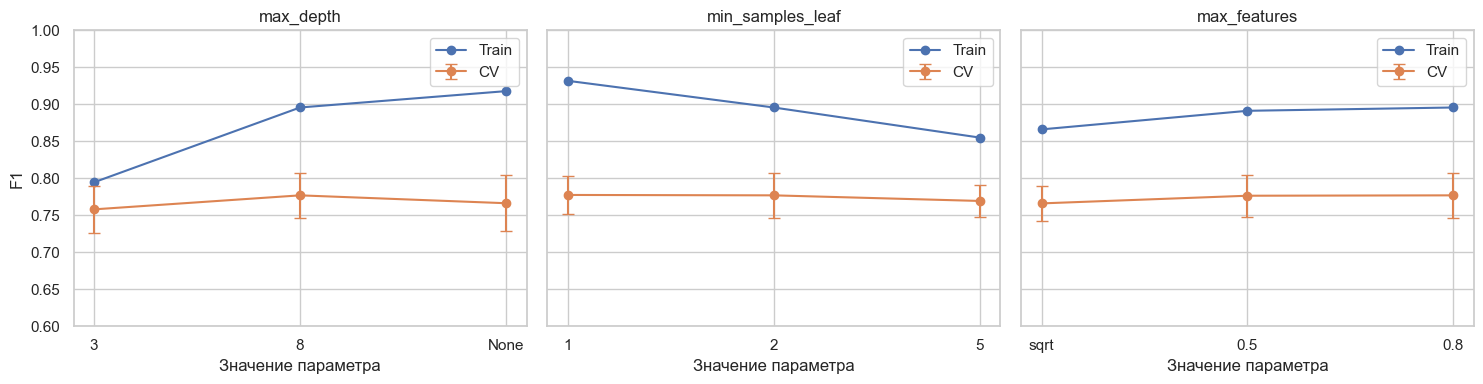

In [7]:
parameter_ranges = {
    "model__max_depth": [3, 8, None],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5, 0.8],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
curve_results = {}

for ax, (parameter, values) in zip(axes, parameter_ranges.items()):
    train_scores, cv_scores = validation_curve(
        baseline, X_train, y_train,
        param_name=parameter, param_range=values,
        cv=cv, scoring="f1", n_jobs=N_JOBS, error_score="raise",
    )
    curve_results[parameter] = {"train": train_scores, "cv": cv_scores}

    positions = range(len(values))
    ax.plot(positions, train_scores.mean(axis=1), marker="o", label="Train")
    ax.errorbar(
        positions, cv_scores.mean(axis=1), yerr=cv_scores.std(axis=1),
        marker="o", capsize=4, label="CV",
    )
    ax.set_xticks(positions, [str(value) for value in values])
    ax.set_title(parameter.replace("model__", ""))
    ax.set_xlabel("Значение параметра")
    ax.set_ylim(0.6, 1.0)
    ax.legend()

axes[0].set_ylabel("F1")
plt.tight_layout()
plt.show()


## 11. Устойчивость результатов

Сравним F1 трёх моделей на каждом фолде, среднее и стандартное отклонение. При близком среднем меньший разброс означает более стабильный результат на этих разбиениях.

,Baseline,Grid Search,Random Search
Фолд,,,
1,0.7778,0.7778,0.7778
2,0.7222,0.7290,0.7290
3,0.8163,0.8081,0.8039
4,0.7843,0.7885,0.7810
5,0.7843,0.7843,0.7925


,Средний F1,Стандартное отклонение,Минимальный F1,Максимальный F1
Baseline,0.7770,0.0305,0.7222,0.8163
Grid Search,0.7775,0.0263,0.7290,0.8081
Random Search,0.7768,0.0256,0.7290,0.8039


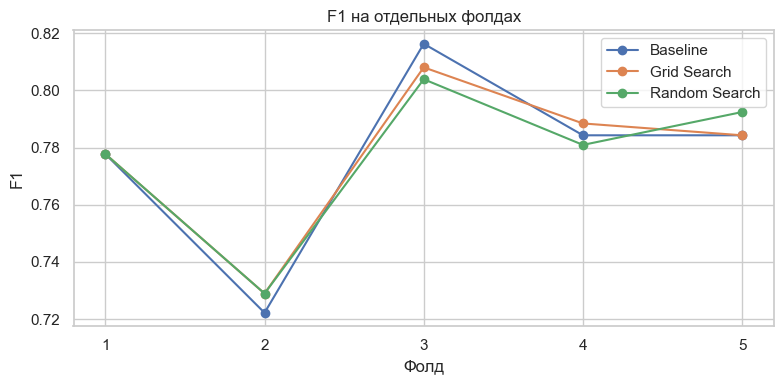

In [10]:
fold_scores = pd.DataFrame({"Baseline": baseline_results["test_score"]})

for name, search in [("Grid Search", grid_search), ("Random Search", random_search)]:
    fold_scores[name] = [
        search.cv_results_[f"split{i}_test_score"][search.best_index_]
        for i in range(CV_FOLDS)
    ]

fold_scores.index = range(1, CV_FOLDS + 1)
fold_scores.index.name = "Фолд"
display(fold_scores.round(4))

stability = pd.DataFrame({
    "Средний F1": fold_scores.mean(),
    "Стандартное отклонение": fold_scores.std(ddof=0),
    "Минимальный F1": fold_scores.min(),
    "Максимальный F1": fold_scores.max(),
})
display(stability.round(4))

fold_scores.plot(marker="o", figsize=(8, 4))
plt.xlabel("Фолд")
plt.ylabel("F1")
plt.xticks(fold_scores.index)
plt.title("F1 на отдельных фолдах")
plt.tight_layout()
plt.show()


## 12. Финальная проверка

По среднему CV F1 выбрана конфигурация Grid Search. Обучим три зафиксированные модели на всём train и сравним их CV F1 и Test F1. После проверки на test параметры не меняем.

In [3]:
final_models = {
    "Baseline": clone(baseline),
    "Grid Search": clone(grid_search.best_estimator_),
    "Random Search": clone(random_search.best_estimator_),
}
selected_name = fold_scores.mean().idxmax()
print("Выбрана по CV:", selected_name)

test_scores = {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    test_scores[name] = f1_score(y_test, model.predict(X_test))

comparison = pd.DataFrame({
    "CV F1": fold_scores.mean(),
    "CV std": fold_scores.std(ddof=0),
    "Test F1": pd.Series(test_scores),
})
comparison["Изменение Test к baseline"] = comparison["Test F1"] - test_scores["Baseline"]
display(comparison.round(4))


Выбрана по CV: Grid Search


,CV F1,CV std,Test F1,Изменение Test к baseline
Baseline,0.7770,0.0305,0.7077,0.0000
Grid Search,0.7775,0.0263,0.7176,0.0099
Random Search,0.7768,0.0256,0.7273,0.0196


## 13. Выводы

Оба поиска проверили по 27 комбинаций на пяти фолдах — по 135 CV-обучений. Число деревьев во всех моделях — 160.

| Модель | CV F1 | Test F1 | Время поиска, с |
|---|---:|---:|---:|
| Baseline | 0.7770 | 0.7077 | — |
| Grid Search | 0.7775 | 0.7176 | 63.3 |
| Random Search | 0.7768 | 0.7273 | 68.3 |

- **Итог:** по CV выбран Grid Search. Относительно baseline прирост составил лишь 0.0005 на CV и 0.0099 на test. Заметного улучшения на CV оптимизация не дала.
- **Сложность модели:** глубина 3 даёт признаки недообучения; без ограничения глубины Train F1 растёт, а CV F1 падает — признаки переобучения. Лист из 1 объекта сильнее подстраивается под train, чем лист из 2 объектов, при почти одинаковом CV F1. Для `max_features` значения 0.5 и 0.8 дали близкое качество.
- **Устойчивость:** стандартное отклонение F1 у baseline — 0.0305, у Grid Search — 0.0263, у Random Search — 0.0256. Настроенные варианты немного стабильнее на этих фолдах. При одинаковом среднем меньший разброс означает меньшую зависимость качества от конкретного разбиения.
- **Зачем CV:** несколько разбиений уменьшают зависимость оценки от одного состава train/validation. Одного train/test недостаточно для подбора: test нужен для итоговой проверки, а параметры выбираются на внутренних разбиениях train. Если многократно выбирать параметры по test, информация из него влияет на настройку и оценка становится оптимистичной.
- **Стратегии поиска:** при одинаковом числе проверок время и качество оказались близкими. Random Search полезен в больших пространствах, где полный перебор дорогой: он проверяет разные значения без обхода всей сетки, но не гарантирует лучший результат.
- **CV и test:** порядок моделей изменился: Random Search немного уступил на CV, но оказался лучше на test. Возможные причины — состав небольшой контрольной выборки и оптимизм лучшего CV score после перебора. Это не повод менять ранее выбранный вариант: Grid Search выбран до просмотра test, после проверки параметры не менялись.
